# 05 · Optional Extension - Three-Class Risk Model (legit / moderate-risk / high-risk)
The brief: *"An optional extension is a three-class model using `prelabel`. Attempt this only after the binary pipeline is working, and **first verify the consistency of those labels**."* The binary pipeline (notebooks 03-04) works, so we proceed - with the verification first.

**Scope decision:** this is a *research side-experiment*. Whether it is deployed is decided at the end, on the evidence below.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, warnings
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, balanced_accuracy_score
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from src.preprocessing import *
from src.train import build_pipeline
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid'); pd.set_option('display.max_columns',None,'display.width',250,'display.max_colwidth',110)
d = pd.read_csv('../data/split.csv'); d['tier'] = d.prelabel.str[0].astype(int)
tr = d[d.split=='train'].reset_index(drop=True); te = d[d.split=='test'].reset_index(drop=True)
print(d.tier.value_counts().sort_index().rename({0:'0 legit',1:'1 moderate',2:'2 high'}))

tier
0 legit       267
1 moderate     88
2 high        288
Name: count, dtype: int64

## 1. Verify label consistency (required first step)
Three checks:
1. **`prelabel` vs `label`** - the tier must agree with the binary label (done in notebook 01: perfectly consistent).
2. **Exact-text duplicates with different tiers** - the raw file's repeated texts: do they ever get different tiers (even when `label` agrees)?
3. **Near-duplicate families with different tiers** - template variants that should have the same severity.

In [2]:
raw = load_raw('../data/scam_detection_labeled.csv'); raw['tier']=raw.prelabel.str[0].astype(int)
print('1) tier vs label crosstab:'); print(pd.crosstab(raw.tier, raw.label))
dup = raw.groupby('text_key').tier.nunique(); print('\n2) exact-text repeats with >1 distinct tier:', int((dup>1).sum()), 'of', int((raw.groupby('text_key').size()>1).sum()), 'repeated texts  (these include the 2 label conflicts)')
sc = d[d.tier>0]; gt = sc.groupby('group').agg(n=('tier','size'), n_tiers=('tier','nunique'))
multi = gt[gt.n>1]; print('3) near-duplicate families of scams with >=2 members:', len(multi), '| of which with mixed moderate/high tiers:', int((multi.n_tiers>1).sum()))

1) tier vs label crosstab:
label  legit  scam
tier              
0        311     0
1          0    92
2          0   333

2) exact-text repeats with >1 distinct tier: 2 of 70 repeated texts  (these include the 2 label conflicts)
3) near-duplicate families of scams with >=2 members: 21 | of which with mixed moderate/high tiers: 0

In [3]:
mixed = multi[multi.n_tiers>1].index
for gname in mixed[:4]:
    print(f'--- family {gname} ---')
    for _,r in d[d.group==gname].iterrows(): print(f'  tier {r.tier}:', r.message_content[:140].replace('\n',' '))

**Findings**
* Tier and binary label are perfectly consistent (check 1).
* Check 2: only the 2 known label-conflict texts differ in tier among the 70 repeated texts - i.e. the annotation is otherwise consistent for exact repeats.
* Check 3: among the 21 scam template families with 2+ members, **none** mixes moderate- and high-risk tiers. So the tiers are applied *consistently to near-identical messages* - a good sign for the extension (consistent is not the same as *correct*, but there is no sign of random tier noise).

**Decision:** proceed, but treat the three-class results as exploratory and judge them against a **majority-class baseline**, with **macro-F1** (which gives the small moderate class equal weight) rather than accuracy.

## 2. Setup
Same leakage-aware protocol as the binary task: the *same* frozen train/test split and grouped folds. Model: multinomial-capable Logistic Regression (multinomial, lbfgs solver) on TF-IDF unigrams + handcrafted features (the configuration the binary experiments preferred), with `class_weight='balanced'` because the moderate class is small (~14%). `C` is tuned by grouped CV on the training set by macro-F1.

In [4]:
X, y, g = tr.message_content.values, tr.tier.values, tr.group.values
folds = [list(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X,y,g)) for s in range(3)]
def cv_macro(pipe):
    out=[]
    for fs in folds:
        pred = np.empty(len(y),int)
        for a,b in fs: pred[b]=clone(pipe).fit(X[a],y[a]).predict(X[b])
        out.append((f1_score(y,pred,average='macro'), balanced_accuracy_score(y,pred), (pred==y).mean()))
    return np.mean(out,0)
rows=[]
for Cv in [0.5,2,8,32]:
    rows.append(dict(C=Cv, **dict(zip(['macro_F1','balanced_acc','accuracy'],cv_macro(build_pipeline('lr',(1,1),True,C=Cv,class_weight='balanced',solver='lbfgs')).round(3)))))
base = DummyClassifier(strategy='most_frequent'); rows.append(dict(C='majority baseline', **dict(zip(['macro_F1','balanced_acc','accuracy'],cv_macro(base).round(3)))))
res = pd.DataFrame(rows); res

,C,macro_F1,balanced_acc,accuracy
0,0.5,0.844,0.838,0.865
1,2,0.857,0.850,0.882
2,8,0.859,0.851,0.883
3,32,0.853,0.845,0.878
4,majority baseline,0.205,0.333,0.445


**Reading:** the baseline always predicts the largest class (high-risk), giving decent *accuracy* but a poor macro-F1 - which is why accuracy alone is misleading here. We pick the `C` with the best macro-F1.

chosen C = 8
              precision    recall  f1-score   support

       legit      0.874     0.874     0.874       214
    moderate      0.797     0.708     0.750        72
        high      0.895     0.926     0.910       229

    accuracy                          0.874       515
   macro avg      0.855     0.836     0.845       515
weighted avg      0.872     0.874     0.873       515

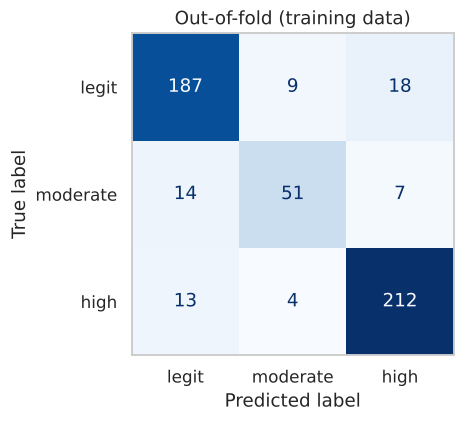

In [5]:
best_C = res.iloc[:4].sort_values('macro_F1',ascending=False).C.iloc[0]; print('chosen C =', best_C)
pipe = build_pipeline('lr',(1,1),True,C=best_C,class_weight='balanced',solver='lbfgs')
# out-of-fold predictions for a confusion matrix on training data
pred = np.empty(len(y),int)
for a,b in folds[0]: pred[b]=clone(pipe).fit(X[a],y[a]).predict(X[b])
names=['legit','moderate','high']
print(classification_report(y,pred,target_names=names,digits=3))
fig,ax=plt.subplots(figsize=(4.2,3.8)); ConfusionMatrixDisplay(confusion_matrix(y,pred),display_labels=names).plot(ax=ax,cmap='Blues',colorbar=False); ax.set_title('Out-of-fold (training data)'); ax.grid(False); plt.show()

## 3. One-time test evaluation

              precision    recall  f1-score   support

       legit      0.857     0.906     0.881        53
    moderate      0.786     0.688     0.733        16
        high      0.914     0.898     0.906        59

    accuracy                          0.875       128
   macro avg      0.852     0.830     0.840       128
weighted avg      0.874     0.875     0.874       128

macro-F1 test: 0.84 | majority baseline macro-F1: 0.21
binary recall via 3-class model: 0.893 | binary precision: 0.931

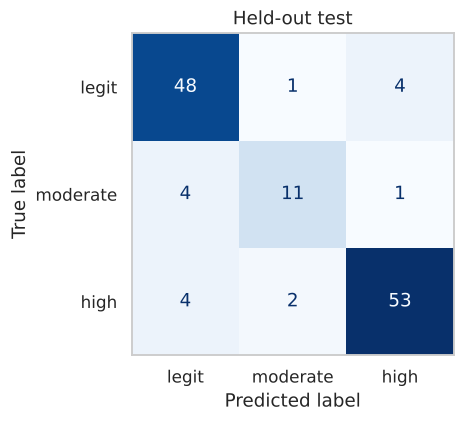

In [6]:
final = clone(pipe).fit(X,y); pt = final.predict(te.message_content.values); yt = te.tier.values
print(classification_report(yt,pt,target_names=names,digits=3))
print('macro-F1 test:', round(f1_score(yt,pt,average='macro'),3), '| majority baseline macro-F1:', round(f1_score(yt,np.full_like(yt,2),average='macro'),3))
fig,ax=plt.subplots(figsize=(4.2,3.8)); ConfusionMatrixDisplay(confusion_matrix(yt,pt),display_labels=names).plot(ax=ax,cmap='Blues',colorbar=False); ax.set_title('Held-out test'); ax.grid(False); plt.show()
# how well does the 3-class model do on the binary question (legit vs any scam)?
bin_pred=(pt>0).astype(int); bin_true=(yt>0).astype(int)
print('binary recall via 3-class model:', round(((bin_pred==1)&(bin_true==1)).sum()/bin_true.sum(),3), '| binary precision:', round(((bin_pred==1)&(bin_true==1)).sum()/max(bin_pred.sum(),1),3))

## 4. Conclusion on the extension
* The **legit vs scam** boundary is learned well, and the **high-risk** tier is reasonably separable (it has distinctive structure: links, money, urgency - notebook 02).
* The **moderate-risk** class is the weak point: its precision/recall are clearly lower, and the confusion matrix shows it being confused with *both* neighbours. This agrees with notebook 02 (moderate-risk scams look structurally almost like legit messages) and with the error analysis in notebook 04 (missed scams are mostly moderate-risk).
* With only ~92 moderate-risk examples, a small test set (~20) and evidence that tier labels are partly subjective, **the three-level output is not reliable enough to show end users**. Decision: **keep the deployed app binary**, and list a verified, larger, multi-annotator three-class dataset as future work.